# Step 3 – Pauli decomposition

Pauli RGB image of every selected scene:

| Colour | Component | Scattering |
|---|---|---|
| Red | \|HH − VV\| | double bounce |
| Green | \|HV + VH\| | volume |
| Blue | \|HH + VV\| | surface |

Results per scene: `<product>_pauli.png`, and a `.tif` with ground control points to open in QGIS/SNAP.
**Output folders**: every run gets its own folder with a time stamp, so earlier results are never overwritten. Inside it, the folders mirror the input folders, so every result can be traced back to its product:
`<OUTPUT_DIR>/<date_time>_<analysis>[_<label>]/<stack folder>/L1C/<product>/<product>_<analysis>.png` (and `.tif`).
Each run folder has a `run_info.json` (settings and scenes of the run), and each stack folder a `stack_info.json` (stack ID, primary, what has been processed).

**How to use**
0. First time only: run **3.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **3.1**, then run **3.1** and **3.2**: they load the tools and list all stacks (with their stack ID) and scenes (★ = primary).
2. Fill in **3.3 Settings**: which stacks and scenes to process.
3. Run **3.4**.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 3.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 3.1 runs without errors.

In [2]:
%pip install --user netCDF4 xarray folium shapely pillow

Note: you may need to restart the kernel to use updated packages.


## 3.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [21]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"  # e.g. "/path/to/biomass_inputs"; None = search automatically
OUTPUT_DIR = "/home/jovyan/idas_dump/test/Nivlisen"  # main folder for all result

## 3.2 Overview of the data

In [22]:
ls

01_Find_Stream_BiomassL1C_stack.ipynb  Bach/              Wilkens.txt
03_pauli.ipynb                         BiomassProduct.py  __pycache__/
04_cloude_pottier.ipynb                Final_Nivlisen/    natural_earth/
05_aoi_map.ipynb                       Input_biomass/     polsar_utils.py
06_circular_basis.ipynb                Nivlisen.txt       untitled1.txt
07_interferometry.ipynb                Output/
BPS_inputs_download.py                 Wilkens/


In [23]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

8 stack(s), 55 scene(s)

[0] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS  (6 scenes)
      [0] 2026-07-04 16:11             BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
      [1] 2026-07-07 16:11             BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
      [2] 2026-07-10 16:11             BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
      [3] 2026-07-13 16:11  ★ primary  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
      [4] 2026-07-19 16:11             BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
      [5] 2026-07-22 16:11             BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
[1] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_2026091

## 3.3 Settings
**Which data**
- `STACKS`: `"all"`, stack names such as `["stack_01", "stack_20"]`, stack IDs (the full ID or just its end, e.g. `["DZ1NQJ"]`), or numbers from the list in 3.2 such as `[0, 2]`
- `SCENES`: `"all"`, `"primary"` (only the primary of each stack), dates such as `["2026-09-15"]`, or numbers within each stack such as `[0, 3]`

Numbers start at 0, as in the list in 3.2.

**Where the results go** (inside `OUTPUT_DIR` from 3.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"window200"`
- `SKIP_EXISTING`: only used when `NEW_RUN_FOLDER = False`: skip scenes that already have a result there (and show the saved result)

**Processing**
- `WINDOW_M`: averaging window in metres (reduces speckle; larger = smoother, less detail)
- `SAVE_GEOTIFF`: also save a GeoTIFF

In [29]:
STACKS = ["DV87RS"]
SCENES = "all"

NEW_RUN_FOLDER = True
RUN_LABEL = "window100"
WINDOW_M = 100
SAVE_GEOTIFF = True
SKIP_EXISTING = True
SHOW_FIGURES = True

## 3.4 Run

Selected 6 scene(s) in 1 stack(s):
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-04 16:11 | BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-07 16:11 | BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-10 16:11 | BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-13 16:11  ★ primary | BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-19 16:11 | BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
   BIO_S1_STA__ID_202607

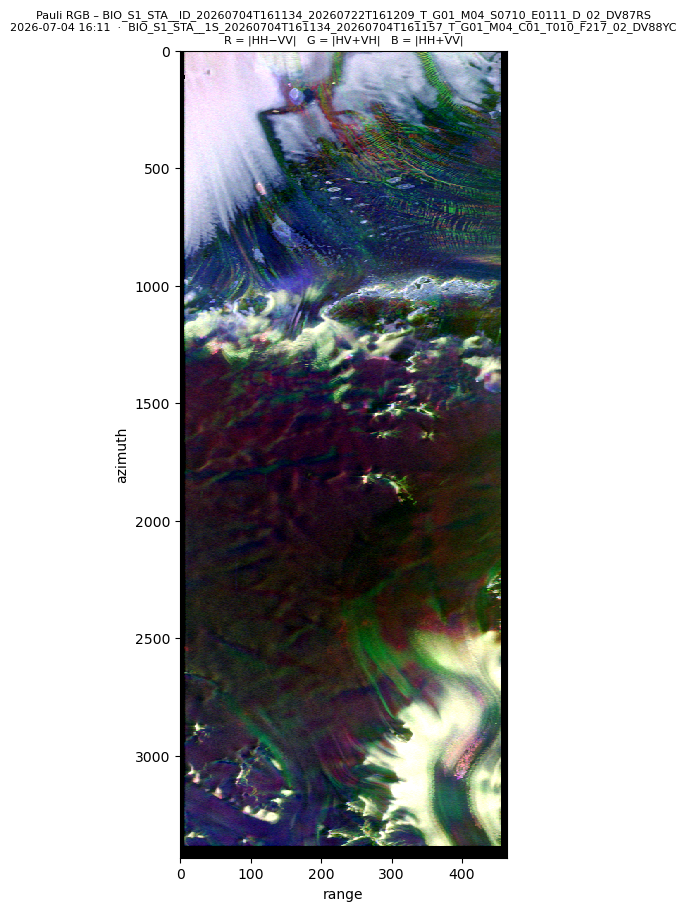

  saved BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC_pauli.png
  saved BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC_pauli.tif

[2/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-07 16:11 | BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  multilook window 15 x 5 pixels (~100 m), ~50 looks


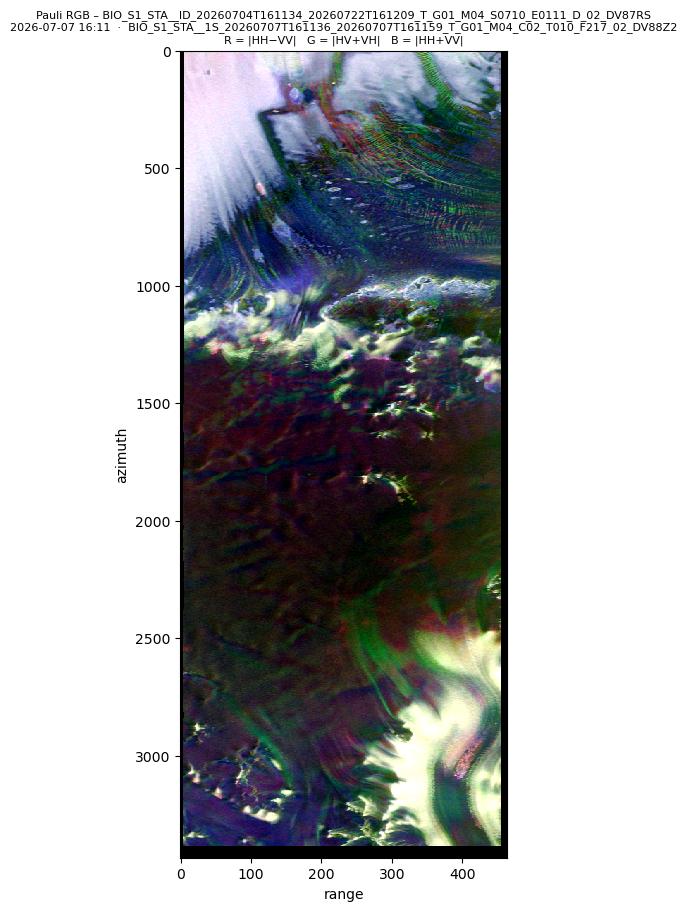

  saved BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2_pauli.png
  saved BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2_pauli.tif

[3/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-10 16:11 | BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  multilook window 15 x 5 pixels (~100 m), ~50 looks


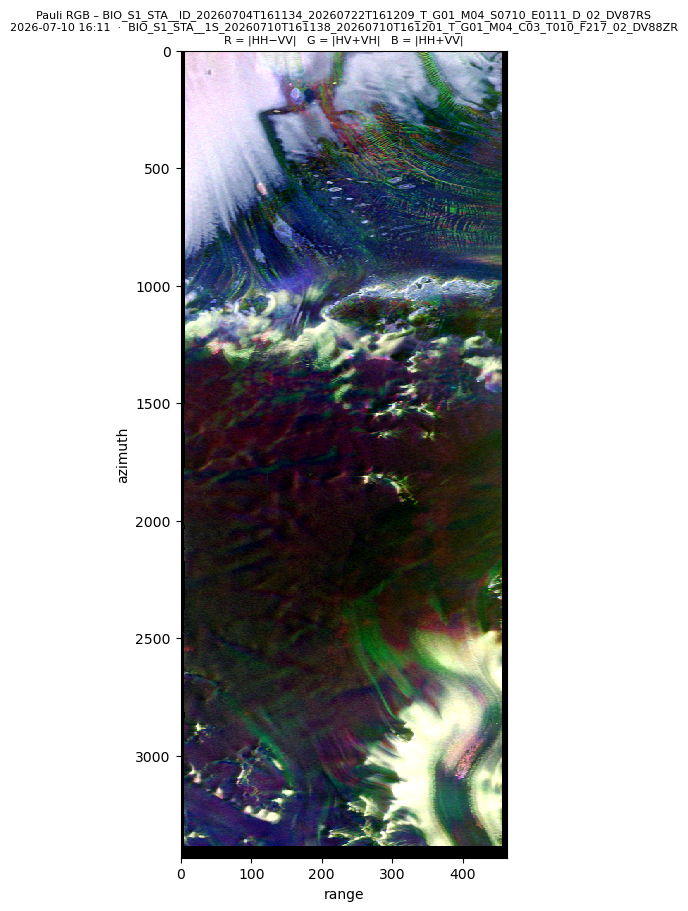

  saved BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR_pauli.png
  saved BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR_pauli.tif

[4/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-13 16:11  ★ primary | BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  multilook window 15 x 5 pixels (~100 m), ~50 looks


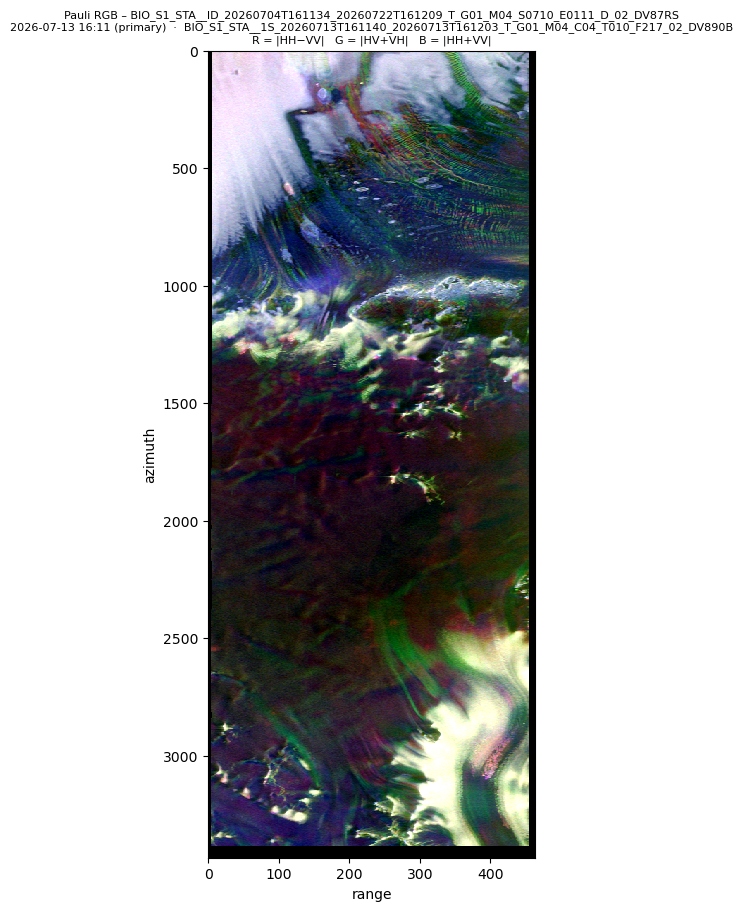

  saved BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B_pauli.png
  saved BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B_pauli.tif

[5/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-19 16:11 | BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  multilook window 15 x 5 pixels (~100 m), ~50 looks


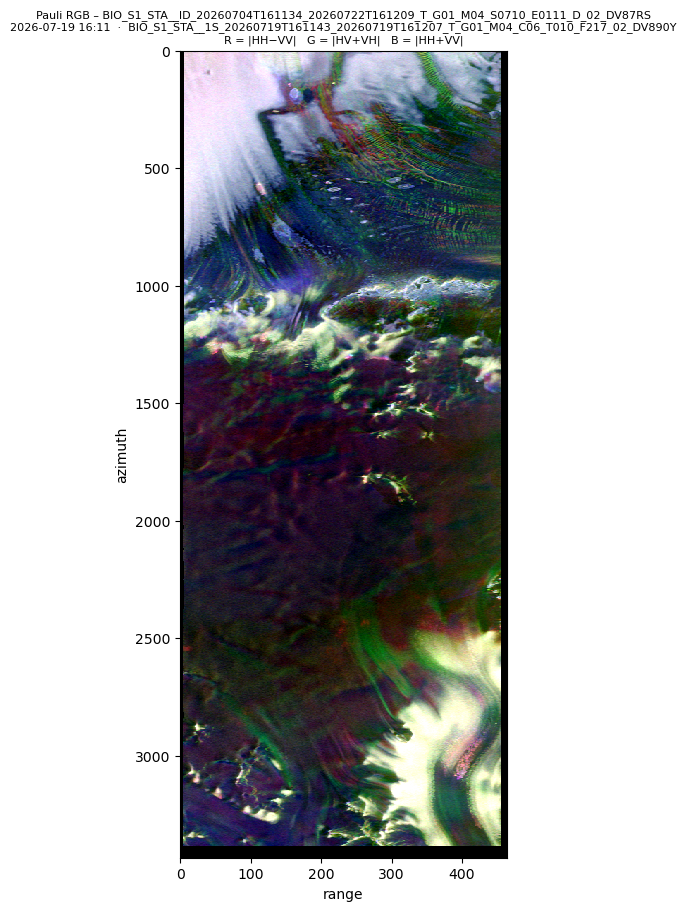

  saved BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y_pauli.png
  saved BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y_pauli.tif

[6/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-22 16:11 | BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
  image 24039 x 928 (azimuth x range), valid pixels 95.4%, phase stored in radians
  multilook window 15 x 5 pixels (~100 m), ~50 looks


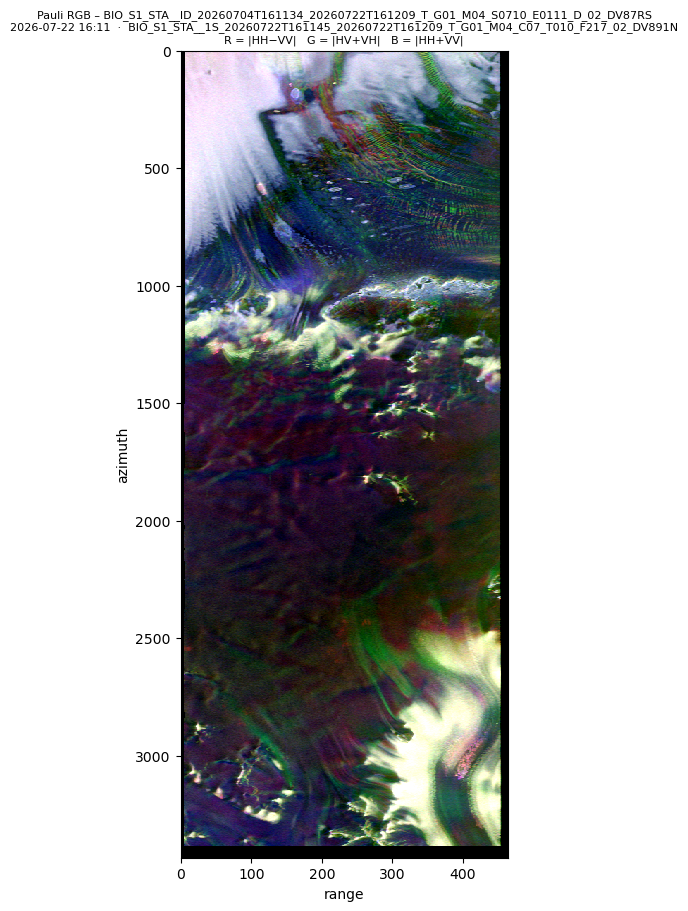

  saved BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N_pauli.png
  saved BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N_pauli.tif

Finished: 6 processed, 0 already done, 0 failed. Results in /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_133614_pauli_window100


[]

In [28]:
scenes = pu.select_scenes(stacks, STACKS, SCENES)
run_dir = pu.new_run_folder(OUTPUT_DIR, "pauli", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(window_m=WINDOW_M, geotiff=SAVE_GEOTIFF, stacks=STACKS, scenes=SCENES), scenes=scenes)
pu.run_pauli(scenes, run_dir, window_m=WINDOW_M, geotiff=SAVE_GEOTIFF,
             skip_existing=SKIP_EXISTING, show=SHOW_FIGURES)

## 3.5 Extra: find the primary of each stack
The primary is the coregistration reference of the stack (`isCoregistrationPrimary` in the product XML).
`PRIMARY_STACKS`: `"all"`, stack names such as `["stack_01"]`, or numbers such as `[0, 2]`.

In [ ]:
PRIMARY_STACKS = "all"

primaries = pu.print_primaries(stacks, PRIMARY_STACKS)